# Third pass: validation, frozen decisions and reproduction

The reference is the entire previous recipe. This notebook reviews common-fold
OOF selection, the frozen new-fold-seed test, and a fair comparison against the
current two-seed model bank. A new partition is a robustness check on previously
explored labels, not an untouched test. A failed gate keeps the previous CSV.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'input').exists():
    ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'input/train.csv').exists())
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve(), 'Use the project local venv'
sys.path.insert(0,str(ROOT/'improvements/round3'))
import round3 as t
import validate as v
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ART=t.ART
print('Python:',sys.executable)
print('Third-pass implementation:',t.implementation_hash())

/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python
Third-pass implementation: a1e121c4ca79cef4ac80c526a939528f09a2c74e0d63d9262dbe29e2aa81f01f


In [2]:
selection=t.read(ART/'selection.json')
display(pd.Series(selection))
rows=[t.read(p) for p in sorted((ART/'cv').glob('*.json'))]
display(pd.DataFrame([dict(model=a['name'],auc=a['auc'],fold_sd=np.std(a['fold_auc'],ddof=1),
                          median_iterations=int(np.median(a['iterations']))) for a in rows]))
display(pd.Series(t.read(ART/'blend_methods.json')))
if (ART/'winner_complementarity.json').exists():display(pd.Series(t.read(ART/'winner_complementarity.json')))

names                  [round2_reference, r3_cat_feature_b512, r3_cat...
weights                                                [0.5, 0.25, 0.25]
method                                                       probability
auc                                                             0.763723
why                    Two complementary helpers with equal new-model...
baseline_auc                                                    0.763089
gain                                                            0.000634
primary_gate_passed                                                 True
fold_gains             [0.0007927774701395052, 0.00044416551709702823...
new_families           [{'name': 'r3_cat_feature_b512', 'spec': {'nam...
confirmation_seed                                               20262209
status                                        frozen before confirmation
dtype: object

,model,auc,fold_sd,median_iterations
0,r3_cat_feature_b512,0.762662,0.003567,1619
1,r3_cat_signed,0.762850,0.003098,1312
2,r3_lgb_proxy,0.759217,0.003562,517


reference_auc                                               0.763089
results            [{'names': ['lgb_tune_15', 'r2_cat_term_proxie...
percentile_note    Primary OOF empirical CDFs use predictions onl...
dtype: object

winner_names                                            [round2_reference, r3_cat_feature_b512, r3_cat...
winner_weights                                                                          [0.5, 0.25, 0.25]
winner_auc                                                                                       0.763723
best_recorded_primary_recipe_with_fewer_new_families    {'names': ['round2_reference', 'r3_cat_signed'...
primary_marginal_gain                                                                            0.000135
correlations                                            [{'a': 'r3_cat_feature_b512', 'b': 'r3_cat_sig...
note                                                    Descriptive complexity check on a frozen prima...
later_descriptive_comparisons                           {'fixed_confirmation': {'frozen_winner_auc': 0...
dtype: object

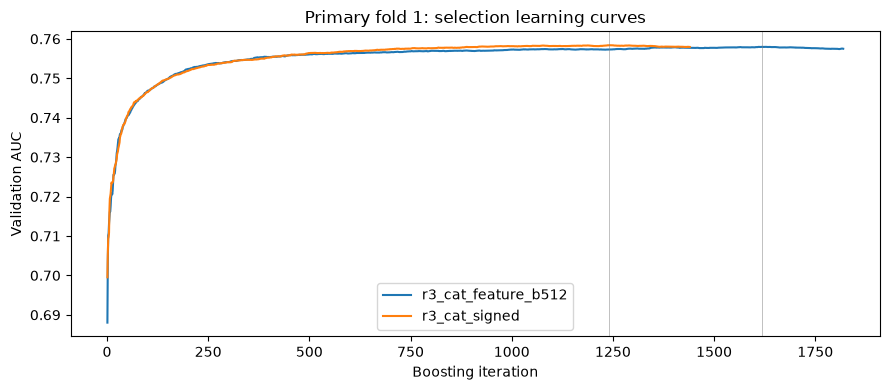

In [3]:
fig,ax=plt.subplots(figsize=(9,4))
drawn=False
for family in selection['new_families']:
    path=ART/'cv'/family['name']/'fold0_curve.json'
    if not path.exists():continue
    curve=t.read(path)
    if isinstance(curve,dict) and 'AUC' in curve.get('validation',{}):
        values=curve['validation']['AUC']
        ax.plot(np.arange(1,len(values)+1),values,label=family['name'])
        ax.axvline(family['iterations'][0],color='gray',linewidth=.7,alpha=.5)
        drawn=True
if drawn:
    ax.set(xlabel='Boosting iteration',ylabel='Validation AUC',title='Primary fold 1: selection learning curves')
    ax.legend();fig.tight_layout();plt.show()
else:plt.close(fig)

## Frozen confirmation and fair seed averaging

The candidate recipe, weights, CDF references and iteration counts are fixed
before confirmation. Confirmation never passes validation labels to model
fitting. Any accepted final bank must also beat the existing two-seed bank;
otherwise a one-seed improvement could disappear through averaging.

baseline_auc                                                          0.762592
candidate_auc                                                         0.763438
gain                                                                  0.000846
fold_gains                   [0.0005013251976125899, 0.0007489511800685689,...
positive_folds                                                               5
passed                                                                    True
fold_seed                                                             20262209
validation_early_stopping                                                False
weights_retuned                                                          False
caveat                       A new partition of previously explored develop...
dtype: object

baseline_two_seed_auc                                                0.763971
candidate_two_seed_auc                                               0.764584
gain                                                                 0.000613
passed                                                                   True
candidate_primary_auc                                                0.763723
candidate_secondary_auc                                              0.763717
secondary_gain_vs_round2                                             0.000841
primary_fold_gains          [0.0009319686410713679, 0.0005371153553833663,...
averaging                   Average matching family predictions across the...
caveat                      Selection/averaging diagnostic on development ...
dtype: object

passed                                                                     True
reference_two_seed            {'auc': 0.7639709612844672, 'average_precision...
reference_three_seed          {'auc': 0.7641962032758703, 'average_precision...
candidate_two_seed            {'auc': 0.7645840648073541, 'average_precision...
candidate_three_seed          {'auc': 0.7648034854637242, 'average_precision...
reference_increment                                                    0.000225
candidate_increment                                                    0.000219
recipe_gain_at_three_seeds                                             0.000607
reference_fold_increments     [0.0005496552159472978, -2.3241949901775527e-0...
candidate_fold_increments     [0.0006577693951486108, 8.980660703872267e-06,...
note                          Conditional development averaging diagnostic. ...
dtype: object

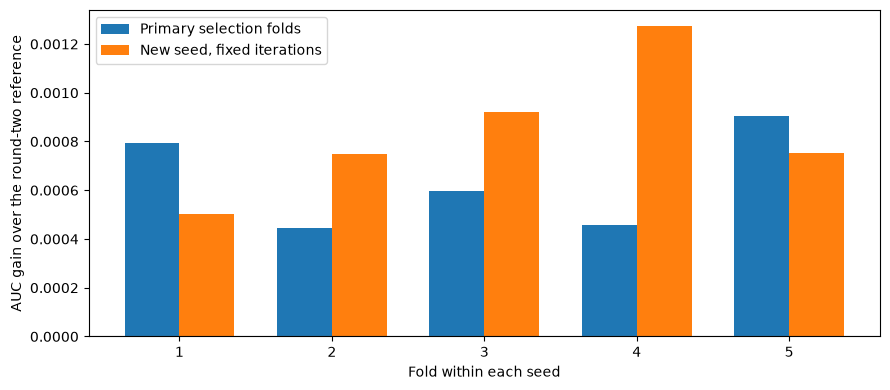

In [4]:
confirm=t.read(ART/'confirmation_results.json')
average=t.read(ART/'averaging_results.json')
display(pd.Series(confirm));display(pd.Series(average))
if (ART/'bagging_probe.json').exists():display(pd.Series(t.read(ART/'bagging_probe.json')))
if 'fold_gains' in confirm:
    fig,ax=plt.subplots(figsize=(9,4))
    xx=np.arange(1,6)
    ax.bar(xx-.18,selection['fold_gains'],.36,label='Primary selection folds')
    ax.bar(xx+.18,confirm['fold_gains'],.36,label='New seed, fixed iterations')
    ax.axhline(0,color='gray',linewidth=.8)
    ax.set(xlabel='Fold within each seed',ylabel='AUC gain over the round-two reference')
    ax.legend();fig.tight_layout();plt.show()

## Final result and saved-model inference

Full-data OOF scores, if a candidate passed, are diagnostics after selection.
They do not change the chosen weights. The public score of a new CSV remains
unknown. Reproduction below loads saved models or verifies the retained CSV.

In [5]:
import finalize
import bagging
result=bagging.preferred_result()
display(pd.Series(result))
bagging.reproduce()
sub=pd.read_csv(ROOT/result['submission'])
assert len(sub)==61500 and list(sub)==['SK_ID_CURR','TARGET']
assert sub.SK_ID_CURR.equals(pd.read_csv(ROOT/'input/sample_submission.csv').SK_ID_CURR)
display(sub.head())

accepted                                                                     True
new_submission_created                                                       True
submission                                    output/submission_round3_bagged.csv
sha256                          7d933ea1e9bffea4e3bf034a81a8ece315655dcebdeb94...
rows                                                                        61500
full_oof                        {'auc': 0.7650709143402641, 'average_precision...
full_oof_independent                                                        False
public_score                                                                 None
recommendation                  Third-pass recipe plus prospectively validated...
probability_min                                                          0.002242
probability_max                                                          0.812805
probability_mean                                                         0.088414
new_saved_models

Three-seed byte-identical reproduction: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/output/submission_round3_bagged_reproduced.csv


,SK_ID_CURR,TARGET
0,171202,0.028844
1,171203,0.204571
2,171204,0.157392
3,171205,0.107229
4,171206,0.176475


Normalized to 100 within each model. Correlated features can share importance. These are descriptive model statistics, not causal effects, and different families use different measures.


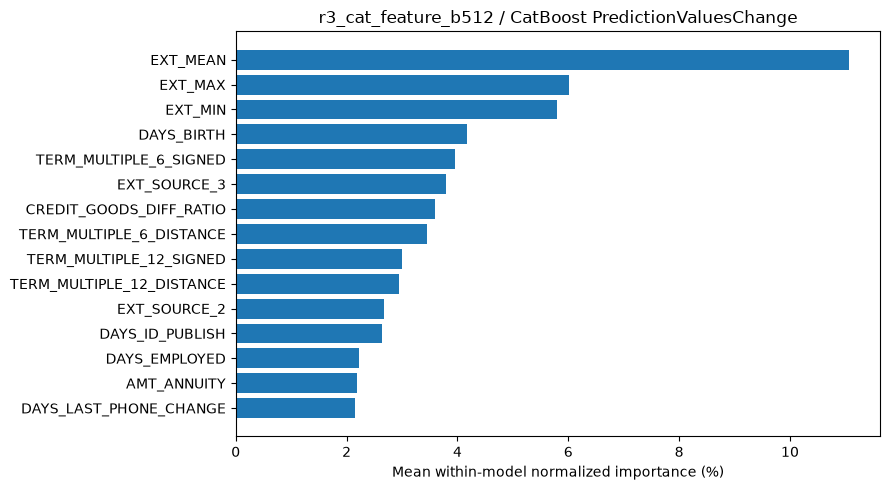

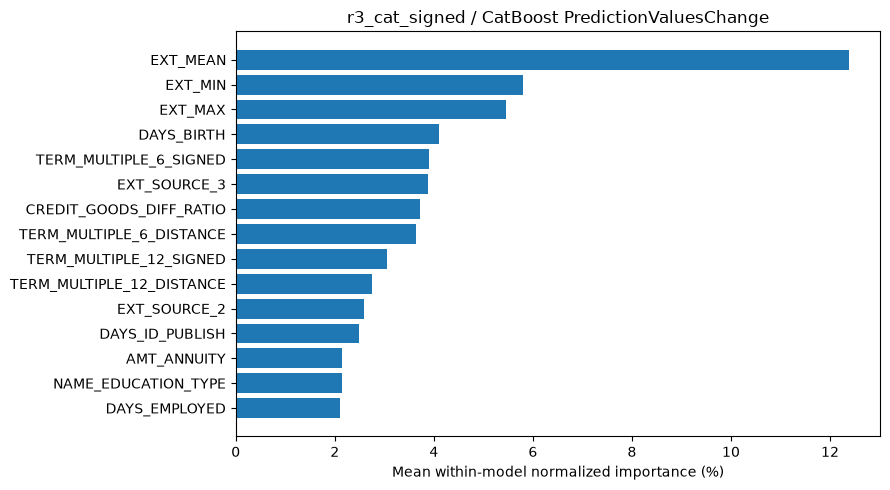

In [6]:
if (ART/'importance_summary.json').exists():
    info=t.read(ART/'importance_summary.json')
    print(info['note'])
    for family in info['families']:
        frame=pd.read_csv(ROOT/family['file']).head(15).sort_values('mean_importance_pct')
        fig,ax=plt.subplots(figsize=(9,5))
        ax.barh(frame.feature,frame.mean_importance_pct)
        ax.set(xlabel='Mean within-model normalized importance (%)',title=family['name']+' / '+family['measure'])
        fig.tight_layout();plt.show()

In [7]:
import hashlib
manifest=t.read(t.HERE/'reference/preserved_hashes.json')
for name,want in manifest.items():
    path=ROOT/name
    if path.exists():assert hashlib.sha256(path.read_bytes()).hexdigest()==want,name
print('Existing notebooks and all present protected artifacts are unchanged.')
print('CSV SHA-256:',hashlib.sha256((ROOT/result['submission']).read_bytes()).hexdigest())

Existing notebooks and all present protected artifacts are unchanged.
CSV SHA-256: 7d933ea1e9bffea4e3bf034a81a8ece315655dcebdeb9408682d159d60bbfb02


## Deliberate full reproduction

Use `.venv/bin/python` from the Competition directory. The phase order is:
`round3.py screen`, `followup.py`, `stacking_probe.py`, `validate.py cv`, `validate.py select`,
`validate.py confirmation`, `validate.py averaging`,
`finalize.py train_final`, `finalize.py reproduce`, then the prospective
`bagging.py probe`, `bagging.py train`, `bagging.py reproduce` check.
The plan and complete journal describe any recorded follow-ups. Input CSVs
and the venv are excluded from the code archive; retain the supplied data.

In [8]:
RUN_VALIDATION_AND_TRAINING=False
if RUN_VALIDATION_AND_TRAINING:
    v.cv();v.select();v.confirmation();v.averaging()
    finalize.train_final();finalize.reproduce()
    bagging.probe();bagging.train();bagging.reproduce()